In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import zipfile
z = zipfile.ZipFile('/content/drive/MyDrive/Pothole_Datasets.zip')
z.extractall()

In [4]:
import os
import shutil

src = 'Pothole_Datasets'
dst_dir = 'datasets'
dst = os.path.join(dst_dir, src)

# Create 'datasets' directory if it doesn't exist
os.makedirs(dst_dir, exist_ok=True)

# If 'pothole_datasets' already exists in 'datasets', remove it
if os.path.exists(dst):
    shutil.rmtree(dst)

# Move 'pothole_datasets' to 'datasets'
shutil.move(src, dst)

print(f"Moved '{src}' to '{dst}' successfully.")

Moved 'Pothole_Datasets' to 'datasets/Pothole_Datasets' successfully.


In [5]:
import yaml

# Define YAML configuration
data = {
    'path': 'Pothole_Datasets',
    'train': 'train/images',
    'val': 'train/images',
    'test': 'test/images',
    'nc': 1,
    'names': ['pothole']
}

# Save to pothole.yaml
with open('pothole.yaml', 'w') as file:
    yaml.dump(data, file, default_flow_style=False)

print("pothole.yaml created successfully!")

pothole.yaml created successfully!


In [6]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 35.2 MB/s eta 0:00:00


In [7]:
from ultralytics import YOLO

# Load a pretrained YOLOv8 model
model = YOLO('yolo11l.pt')  # 'yolov8s.pt' or 'yolov8m.pt' for better accuracy

# Train the model and save only the best checkpoint
model.train(
    data='pothole.yaml',
    epochs=50,
    imgsz=640,
    batch=8,
    name='pothole_yolov8',
    save=True,
    save_period=-1,  # Don't save every epoch
    patience=20,     # Early stopping if no improvement for 20 epochs (optional)
    val=False         # Run validation during training to select best model
)


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.235 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=pothole.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, l

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78e80e1c8200>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [8]:
def draw_boxes(image, box, label, color_sample):

    image_with_boxes = image.copy()

    xmin, ymin, xmax, ymax = map(int, box)

    # Ensure correct indexing
    color = random.choice(color_sample)

    # Draw bounding box
    cv2.rectangle(image_with_boxes, (xmin, ymin), (xmax, ymax), color, 2)

    # Draw label text
    text = label
    text_size, _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 1, 3)
    text_w, text_h = text_size

    # Adjust text position to prevent out-of-bounds
    ymin_text = max(ymin - text_h - 5, 0)

    # Background rectangle for text
    cv2.rectangle(image_with_boxes, (xmin, ymin_text-5), (xmin + text_w + 10, ymin), color, -1)

    # Put text on the image with white color for better visibility
    cv2.putText(
        image_with_boxes,
        text,
        (xmin + 5, ymin - 5),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 0, 0),  # White text
        2,
        cv2.LINE_AA,
    )

    return image_with_boxes


image 1/1 /content/datasets/Pothole_Datasets/test/holes-in-the-street.jpg: 448x640 7 potholes, 38.0ms
Speed: 1.9ms preprocess, 38.0ms inference, 1.2ms postprocess per image at shape (1, 3, 448, 640)

image 1/1 /content/datasets/Pothole_Datasets/test/car-hits-pothole-in-road-splashes-water-car-runs-into-bad-ro.jpg: 384x640 1 pothole, 28.4ms
Speed: 1.6ms preprocess, 28.4ms inference, 1.1ms postprocess per image at shape (1, 3, 384, 640)

image 1/1 /content/datasets/Pothole_Datasets/test/pot-hole (2).jpg: 512x640 3 potholes, 55.0ms
Speed: 2.0ms preprocess, 55.0ms inference, 1.1ms postprocess per image at shape (1, 3, 512, 640)

image 1/1 /content/datasets/Pothole_Datasets/test/pot-hole (5).jpg: 640x448 1 pothole, 32.2ms
Speed: 1.7ms preprocess, 32.2ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 448)

image 1/1 /content/datasets/Pothole_Datasets/test/holes-in-the-street.jpg: 448x640 7 potholes, 28.3ms
Speed: 1.8ms preprocess, 28.3ms inference, 1.1ms postprocess per image a

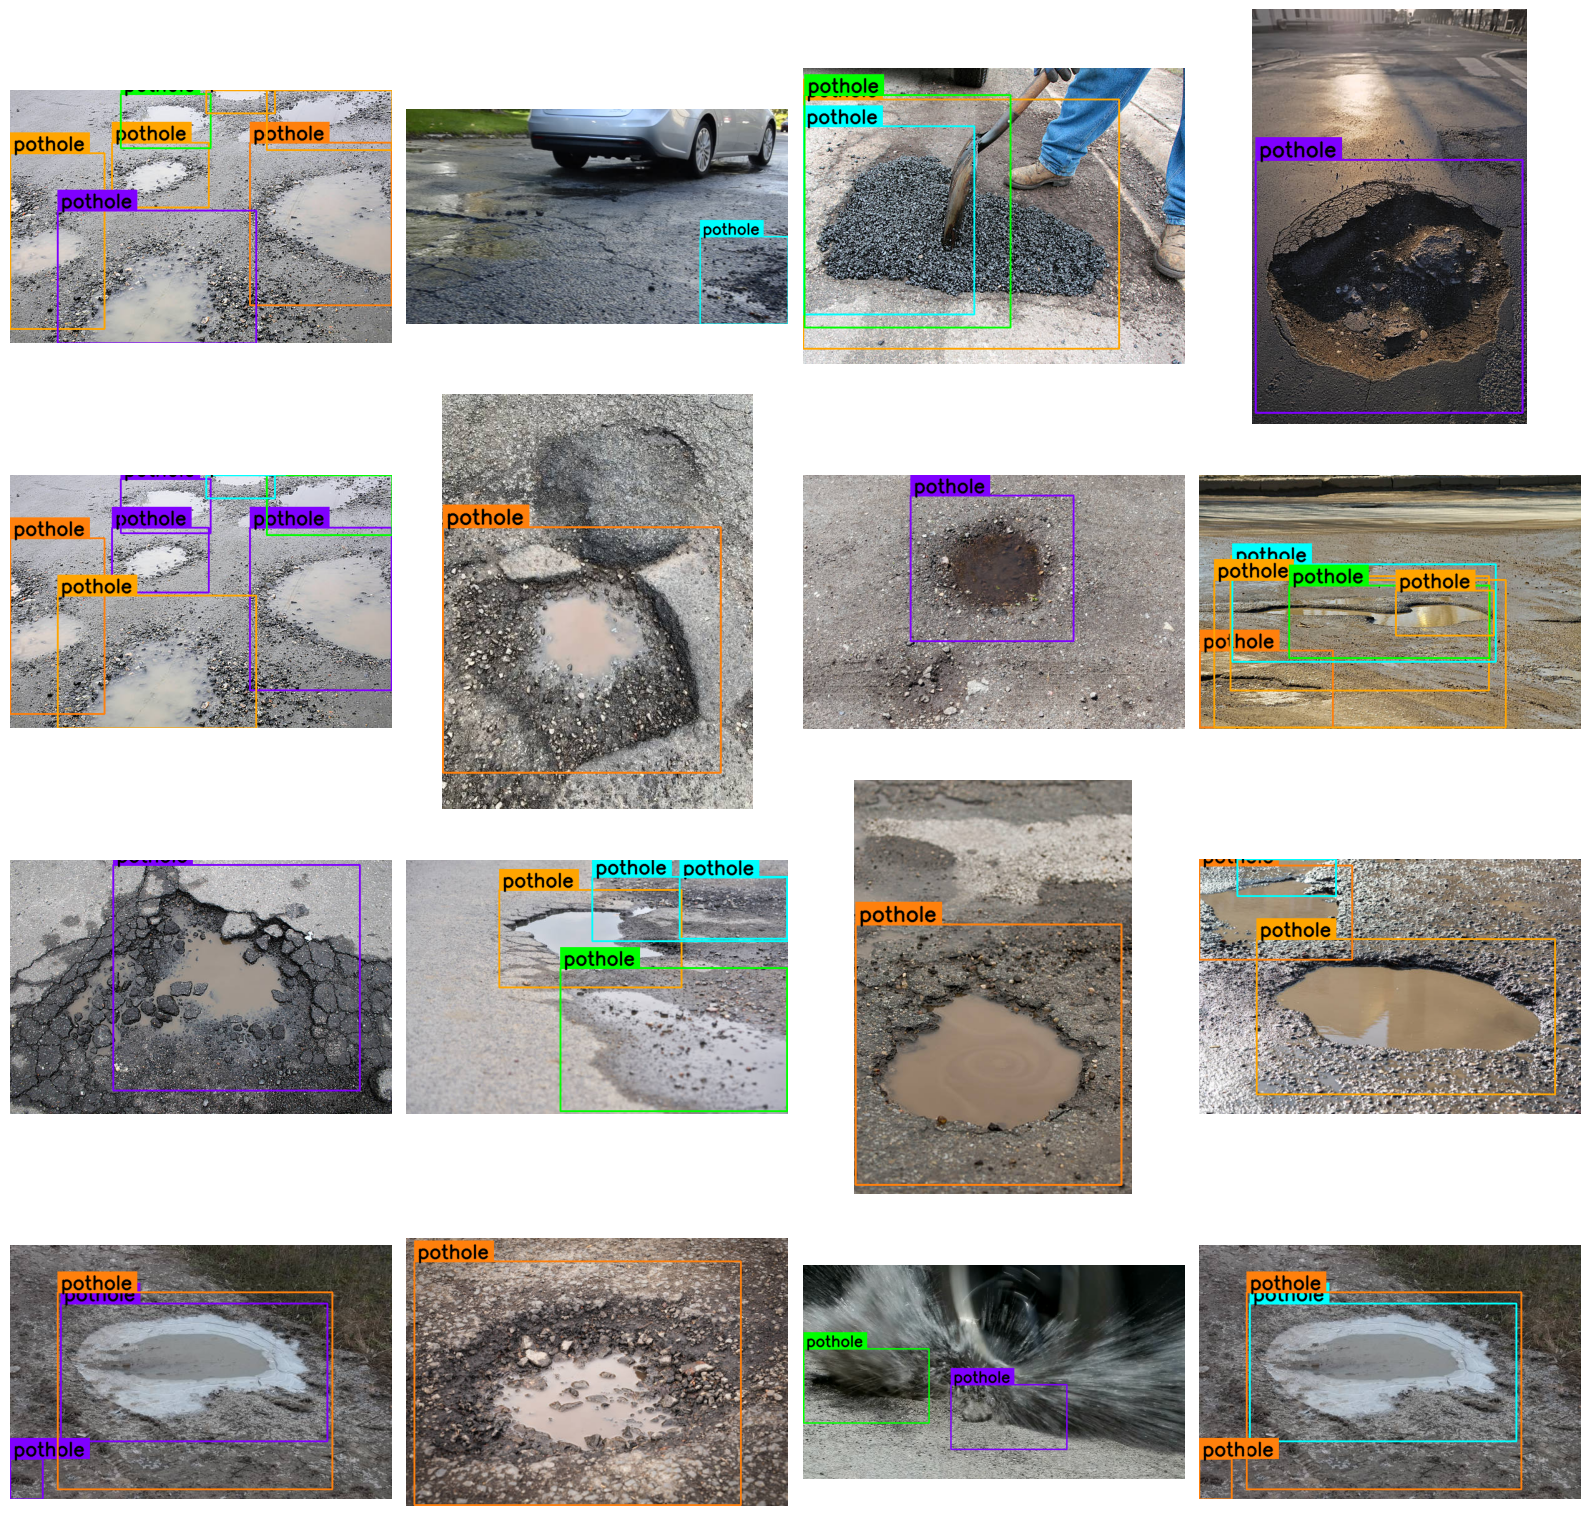

In [10]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import os
import random

# Load trained model
model = YOLO('runs/detect/pothole_yolov8/weights/best.pt')

# Test images directory
test_images_dir = 'datasets/Pothole_Datasets/test'

color_sample = [
    (12, 128, 255),   # Orange-ish
    (255, 0, 127),    # Pink
    (0, 255, 0),      # Green
    (255, 255, 0),    # Cyan
    (0, 165, 255)     # Blue-ish
]

# Get list of test images (max 16)
image_files = os.listdir(test_images_dir)

# Plot settings
fig, ax = plt.subplots(4, 4, figsize=(16, 16))
ax = ax.ravel()

for idx in range(16):
    img_name = random.choice(image_files)
    img_path = os.path.join(test_images_dir, img_name)
    image = cv2.imread(img_path)

    # Inference
    results = model(img_path)[0]  # Get first result (one image)

    # Draw each box if confidence > 0.8
    for box in results.boxes:

        xyxy = map(int, box.xyxy[0])
        cls_id = int(box.cls[0])
        label = model.names[cls_id]
        image = draw_boxes(image, xyxy, label, color_sample)

    # Convert BGR to RGB for plotting
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Plot
    ax[idx].imshow(image_rgb)
    ax[idx].axis('off')

plt.tight_layout()
plt.show()

In [11]:
!zip -r /content/runs.zip /content/runs

  adding: content/runs/ (stored 0%)
  adding: content/runs/detect/ (stored 0%)
  adding: content/runs/detect/pothole_yolov8/ (stored 0%)
  adding: content/runs/detect/pothole_yolov8/val_batch2_labels.jpg (deflated 7%)
  adding: content/runs/detect/pothole_yolov8/train_batch2.jpg (deflated 3%)
  adding: content/runs/detect/pothole_yolov8/args.yaml (deflated 53%)
  adding: content/runs/detect/pothole_yolov8/confusion_matrix.png (deflated 36%)
  adding: content/runs/detect/pothole_yolov8/labels.jpg (deflated 31%)
  adding: content/runs/detect/pothole_yolov8/results.csv (deflated 68%)
  adding: content/runs/detect/pothole_yolov8/results.png (deflated 13%)
  adding: content/runs/detect/pothole_yolov8/val_batch2_pred.jpg (deflated 6%)
  adding: content/runs/detect/pothole_yolov8/BoxR_curve.png (deflated 17%)
  adding: content/runs/detect/pothole_yolov8/confusion_matrix_normalized.png (deflated 36%)
  adding: content/runs/detect/pothole_yolov8/val_batch1_pred.jpg (deflated 7%)
  adding: conte